# Replay protection experiment analysis

This notebook delegates all validation and metric recomputation to `analyze_replay_protection.py`. It refuses to present a comparison when the 12-configuration matrix, request observations, protected-operation evidence, or recorded summary is incomplete or inconsistent.

The experiment directory below is explicit. Replace it with the path printed by the latest full run when analyzing another dataset.


In [1]:
from pathlib import Path
import json
import subprocess
import sys

project_root = Path.cwd()
if not (project_root / "run-local-demo-2.js").exists():
    project_root = project_root.parent
experiment_dir = project_root / "results/replay-2026-11-12T21-04-35-038Z-24266fa7"
analysis_script = project_root / "analysis" / "analyze_replay_protection.py"

result = subprocess.run(
    [sys.executable, str(analysis_script), str(experiment_dir)],
    text=True,
    capture_output=True,
)
print(result.stdout)
if result.stderr:
    print(result.stderr)
if result.returncode:
    raise RuntimeError("Experiment validation failed; do not compare this dataset.")

analysis_dir = experiment_dir / "analysis"
validation = json.loads((analysis_dir / "validation_report.json").read_text())
assert validation["valid"] is True


{
  "experiment_id": "replay-2026-11-12T21-04-35-038Z-24266fa7",
  "valid": true,
  "scenario_rows": 36,
  "valid_scenarios": 36,
  "invalid_scenarios": 0,
  "comparison_generated": true,
  "failures": []
}
Analysis outputs: /home/nasyikhqusyairy/Projects/repositories/mse/results/replay-2026-11-12T21-04-35-038Z-24266fa7/analysis



In [2]:
import pandas as pd
from IPython.display import display, Image

validation_rows = pd.read_csv(analysis_dir / "scenario_validation.csv")
derived_metrics = pd.read_csv(analysis_dir / "derived_metrics.csv")
method_comparison = pd.read_csv(analysis_dir / "method_comparison.csv")
requests = pd.read_csv(experiment_dir / "requests.csv")
summary = pd.read_csv(experiment_dir / "summary.csv")

print(f"Validated {validation['valid_scenarios']} of {validation['scenario_rows']} scenario/repetition rows")
display(validation_rows)
display(method_comparison)


Validated 36 of 36 scenario/repetition rows


,scenario_id,method,replica_count,repetition,valid,validation_errors
0,S1,in-memory,1,1,True,NaN
1,S1,in-memory,1,2,True,NaN
2,S1,in-memory,1,3,True,NaN
3,S2,redis,1,1,True,NaN
4,S2,redis,1,2,True,NaN
5,S2,redis,1,3,True,NaN
6,S3,redis-ttl,1,1,True,NaN
7,S3,redis-ttl,1,2,True,NaN
8,S3,redis-ttl,1,3,True,NaN
9,S4,mysql,1,1,True,NaN


,method,replica_count,replay_detection_rate,legitimate_request_acceptance_rate,false_rejection_rate,false_acceptance_rate,cross_replica_replay_detection_rate,latency_mean_ms,latency_median_ms,latency_p95_ms,latency_p99_ms,throughput_rps,store_latency_mean_ms,store_latency_p95_ms,store_error_count,request_error_count,service_error_count,protected_operation_execution_count,restart_state_retained
0,in-memory,1,0.993750,1.0,0.0,0.006250,NaN,31.757452,16.314864,86.003769,93.274764,318.690682,0.019701,0.031800,0.0,0.0,0.0,405.0,0.0
1,in-memory,2,0.975155,1.0,0.0,0.024845,0.0,39.442991,17.808318,107.969337,112.595702,282.580097,0.027802,0.047760,0.0,0.0,0.0,409.0,0.0
2,in-memory,3,0.962733,1.0,0.0,0.037267,0.0,40.269513,34.584179,86.064118,89.032569,265.702126,0.037719,0.073028,0.0,0.0,0.0,411.0,0.0
3,mysql,1,1.000000,1.0,0.0,0.000000,NaN,45.247661,23.858686,120.348299,126.414259,212.571297,9.781095,24.459115,0.0,0.0,0.0,404.0,1.0
4,mysql,2,1.000000,1.0,0.0,0.000000,1.0,39.321420,19.841106,107.188904,112.091091,248.564692,6.833139,17.901508,0.0,0.0,0.0,405.0,1.0
5,mysql,3,1.000000,1.0,0.0,0.000000,1.0,36.746430,18.954265,94.412244,98.907525,252.369038,5.918255,16.131725,0.0,0.0,0.0,405.0,1.0
6,redis,1,1.000000,1.0,0.0,0.000000,NaN,38.814834,20.575382,99.614016,103.020667,304.868601,4.148467,13.525084,0.0,0.0,0.0,404.0,1.0
7,redis,2,1.000000,1.0,0.0,0.000000,1.0,37.060709,17.565933,96.384011,99.495255,310.416952,1.474135,5.500917,0.0,0.0,0.0,405.0,1.0
8,redis,3,1.000000,1.0,0.0,0.000000,1.0,32.143481,15.794055,81.663243,85.689033,322.061227,0.552064,1.536202,0.0,0.0,0.0,405.0,1.0
9,redis-ttl,1,1.000000,1.0,0.0,0.000000,NaN,38.580076,18.345221,105.478246,107.532131,320.019868,4.088683,13.658857,0.0,0.0,0.0,404.0,1.0


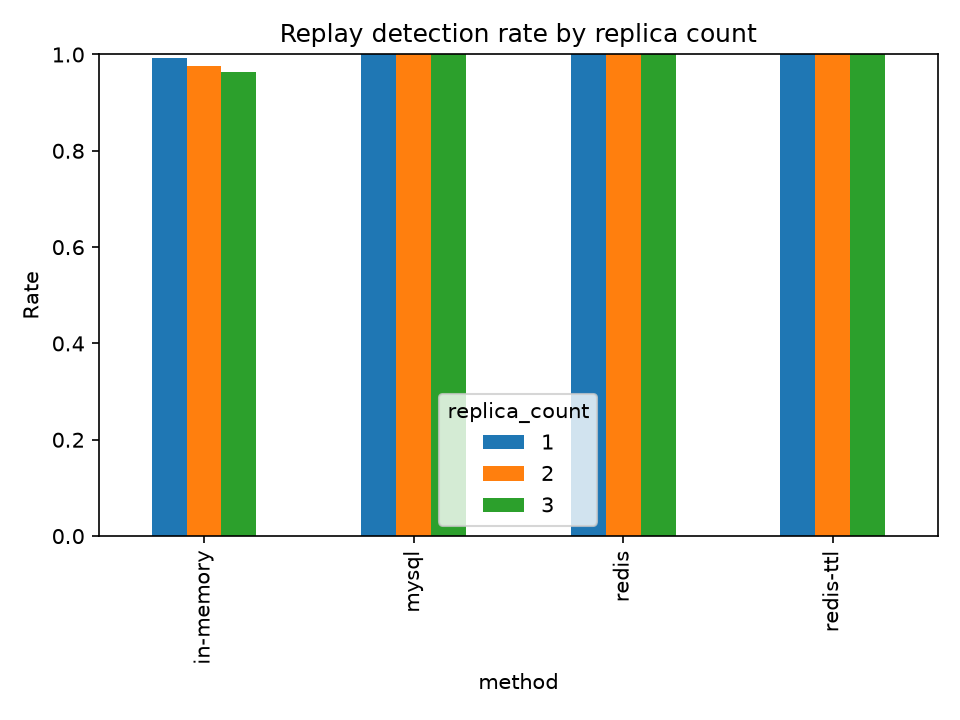

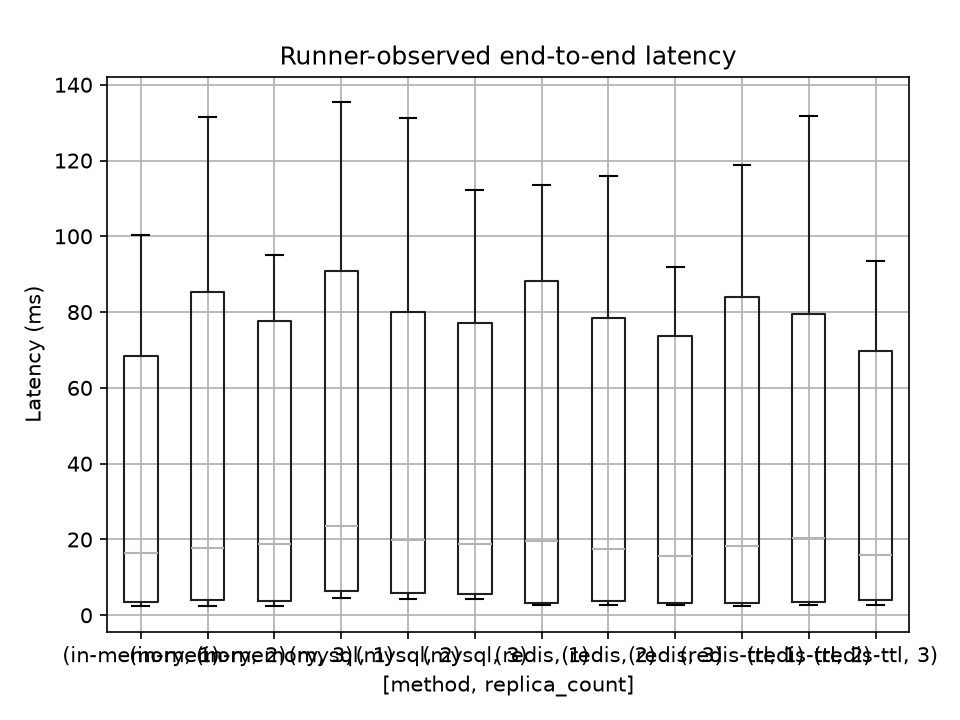

In [3]:
display(Image(filename=str(analysis_dir / "security_rates.png")))
display(Image(filename=str(analysis_dir / "latency_by_method.png")))


## Metric definitions

- Replay detection rate: detected serial replays plus detected concurrent duplicate attempts, divided by serial replay attempts plus (concurrent batch size minus one) per batch.
- False acceptance rate: accepted serial replay attempts plus concurrent acceptances beyond the first per `jti`, divided by that same replay-attempt denominator.
- Legitimate acceptance and false rejection: accepted or non-accepted observed legitimate first-use/performance requests divided by the number of those observed requests.
- Cross-replica rate: detected cross-replica replay observations divided by observed cross-replica replay requests; one-replica cases are not applicable.
- Latency percentiles and replay-store latency are recomputed from measured request rows. Throughput is completed performance requests divided by their observed wall-clock span.
- Protected-operation count includes only rows whose explicit Order Service response header confirms the protected handler executed. Missing evidence remains missing and invalidates the run.
